In [10]:
library(tidyverse)
library(pheatmap)

In [81]:
col.data <- read.delim("~/manuscripts/BAF_stimulus_CellGenomics/figures/Figure4/PanelC/IFNy_Dex_DEGs_coldata.tsv", sep='\t')
row.data <- read.delim("~/manuscripts/BAF_stimulus_CellGenomics/figures/Figure4/PanelC/IFNy_Dex_DEGs_rowdata.tsv", sep='\t')
tpm <- read.delim("~/manuscripts/BAF_stimulus_CellGenomics/figures/Figure4/PanelC/IFNy_Dex_DEGs_TPMs.tsv", sep='\t')

#read in DEGs
ifn_1h <- read.delim("~/manuscripts/BAF_stimulus_CellGenomics/inputs/DEGs/GM12878/BAFinh_stimulus/IFNy_1h_DEGs.tsv", sep='\t')
ifn_6h <- read.delim("~/manuscripts/BAF_stimulus_CellGenomics/inputs/DEGs/GM12878/BAFinh_stimulus/IFNy_6h_DEGs.tsv", sep='\t')
dex_1h <- read.delim("~/manuscripts/BAF_stimulus_CellGenomics/inputs/DEGs/GM12878/BAFinh_stimulus/Dex_1h_DEGs.tsv", sep='\t')
dex_6h <- read.delim("~/manuscripts/BAF_stimulus_CellGenomics/inputs/DEGs/GM12878/BAFinh_stimulus/Dex_6h_DEGs.tsv", sep='\t')

brm_6h <- read.delim("~/manuscripts/BAF_stimulus_CellGenomics/inputs/DEGs/GM12878/BAFinh_stimulus/BRM_6h_DEGs.tsv", sep='\t')

brm_ifn_6h <- read.delim("~/manuscripts/BAF_stimulus_CellGenomics/inputs/DEGs/GM12878/BAFinh_stimulus/BRM_IFNy_v_IFNy_6h_DEGs.tsv", sep='\t')
brm_dex_6h <- read.delim("~/manuscripts/BAF_stimulus_CellGenomics/inputs/DEGs/GM12878/BAFinh_stimulus/BRM_Dex_v_Dex_6h_DEGs.tsv", sep='\t')


ifn_up <- (ifn_1h$change=="up"  | ifn_6h$change=="up")
dex_up <- (dex_1h$change=="up"  | dex_6h$change=="up")

In [35]:
col.data_ifn <- col.data[grep("IFN|Veh",col.data$group),]
tpm_ifn <- tpm[,grep("IFN|Veh",col.data$group)] %>% `colnames<-`(col.data_ifn$group)
head(tpm_ifn)

col.data_dex <- col.data[grep("Dex|Veh",col.data$group),]
tpm_dex <- tpm[,grep("Dex|Veh",col.data$group)] %>% `colnames<-`(col.data_dex$group)
head(tpm_dex)

,BRM_IFN_T1,BRM_IFN_T1,IFN_T1,IFN_T1,Veh_T1,Veh_T1,BRM_IFN_T6,BRM_IFN_T6,IFN_T6,IFN_T6,Veh_T6,Veh_T6
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,57.89,53.07,55.57,60.77,57.17,60.77,59.02,59.23,60.71,59.59,64.56,57.29
2,12.86,14.88,17.98,10.78,14.29,13.70,23.96,22.85,13.30,16.77,12.54,15.56
3,450.90,401.70,438.32,411.00,396.87,382.82,567.30,581.59,625.20,568.06,456.13,402.24
4,22.17,21.91,25.35,23.60,24.38,20.99,22.66,20.54,18.56,22.07,21.92,25.48
5,9.59,11.00,10.30,11.14,11.55,10.03,19.03,16.87,13.86,12.30,9.96,10.29
6,9.99,10.36,10.14,12.03,9.75,10.69,5.81,8.38,8.01,8.09,11.73,10.44


,BRM_Dex_T1,BRM_Dex_T1,Dex_T1,Dex_T1,Veh_T1,Veh_T1,BRM_Dex_T6,BRM_Dex_T6,Dex_T6,Dex_T6,Veh_T6,Veh_T6
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,60.73,56.71,58.87,54.82,57.17,60.77,60.43,60.89,63.03,57.85,64.56,57.29
2,13.33,12.32,16.15,14.89,14.29,13.70,22.93,25.07,12.13,14.80,12.54,15.56
3,402.33,363.47,380.40,356.99,396.87,382.82,218.72,235.92,269.01,241.99,456.13,402.24
4,22.11,20.70,22.21,24.71,24.38,20.99,17.08,19.47,16.21,18.05,21.92,25.48
5,10.23,10.87,9.65,10.69,11.55,10.03,17.28,18.26,11.32,10.96,9.96,10.29
6,9.06,11.37,10.87,10.42,9.75,10.69,5.38,8.30,12.39,12.57,11.73,10.44


In [42]:
hm_scale <- function(tpms,coldata,groups, scale="none", breaks=NA, colors=c("white", "red")){
    temp <- tpms[,coldata$group %in% groups] %>% +1 %>% log2()
    temp_coldata <- coldata[coldata$group %in% groups,]
    max <- max(temp) + 1
    
    d <- dist(scale(temp))
    h <- hclust(d)
    
    pheatmap(temp[h$order,], 
             color=colorRampPalette(colors)(100), 
             cluster_rows=if (scale=="row") TRUE else FALSE, 
             cluster_cols=FALSE, 
             border_col=NA, 
             labels_col=temp_coldata$group,
             show_rownames=FALSE,
             scale=scale,
             breaks= breaks,
             cellheight=1, 
             main=paste("n=", nrow(temp)))
}

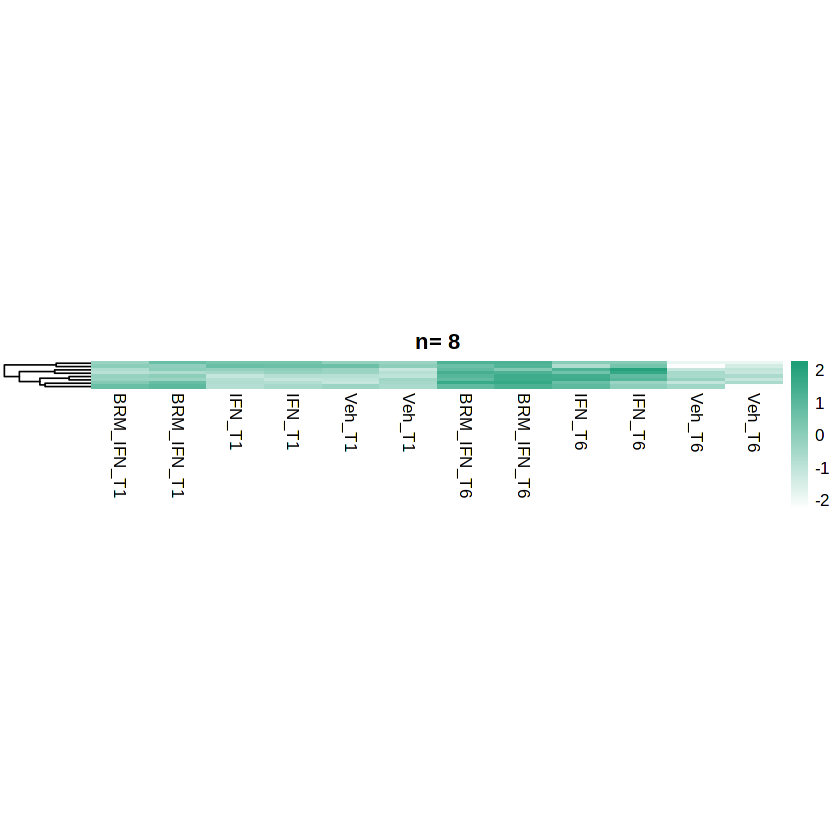

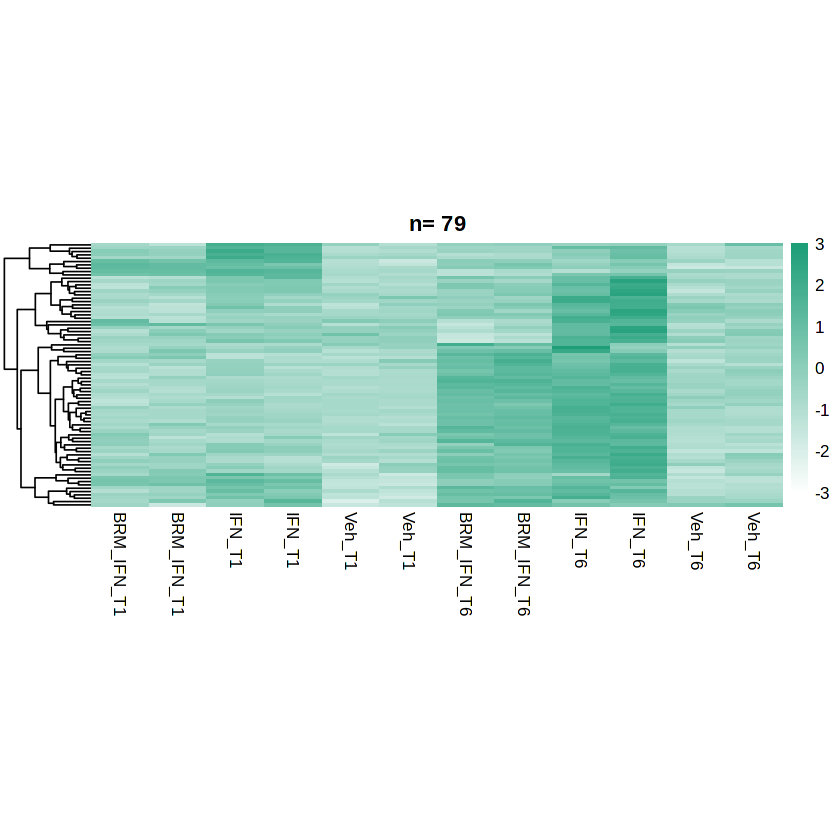

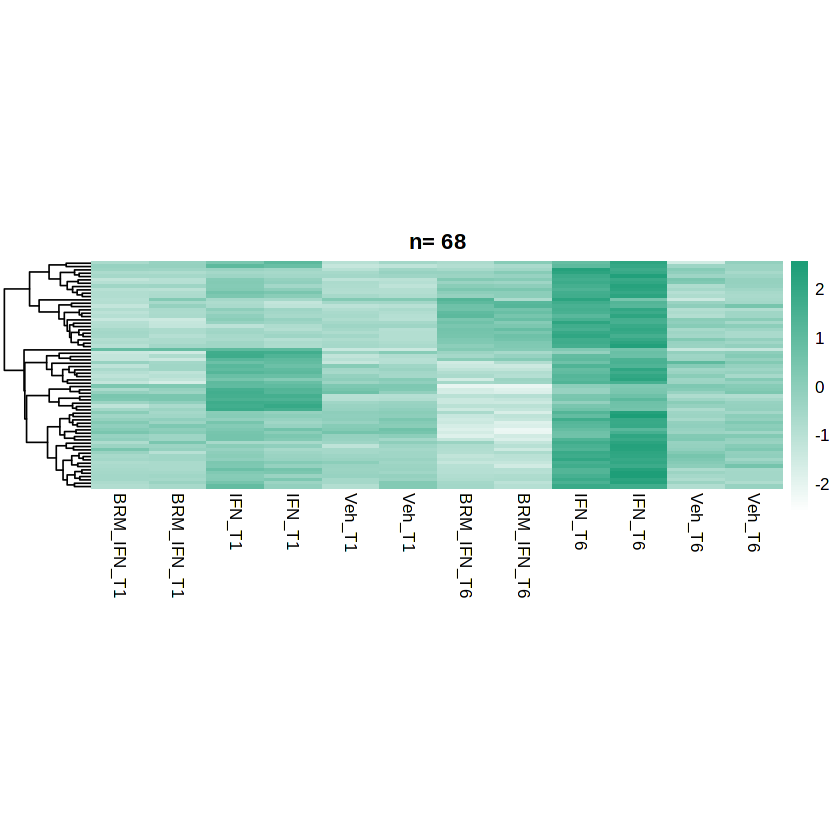

In [39]:
hm_scale(tpm_ifn[which(ifn_up & brm_6h$change=="up"),], col.data_ifn, col.data_ifn$group, scale="row", colors=c("white", "#1c9e77"))
hm_scale(tpm_ifn[which(ifn_up & brm_6h$change=="ns"),], col.data_ifn, col.data_ifn$group, scale="row", colors=c("white", "#1c9e77"))
hm_scale(tpm_ifn[which(ifn_up & brm_6h$change=="down"),], col.data_ifn, col.data_ifn$group, scale="row", colors=c("white", "#1c9e77"))

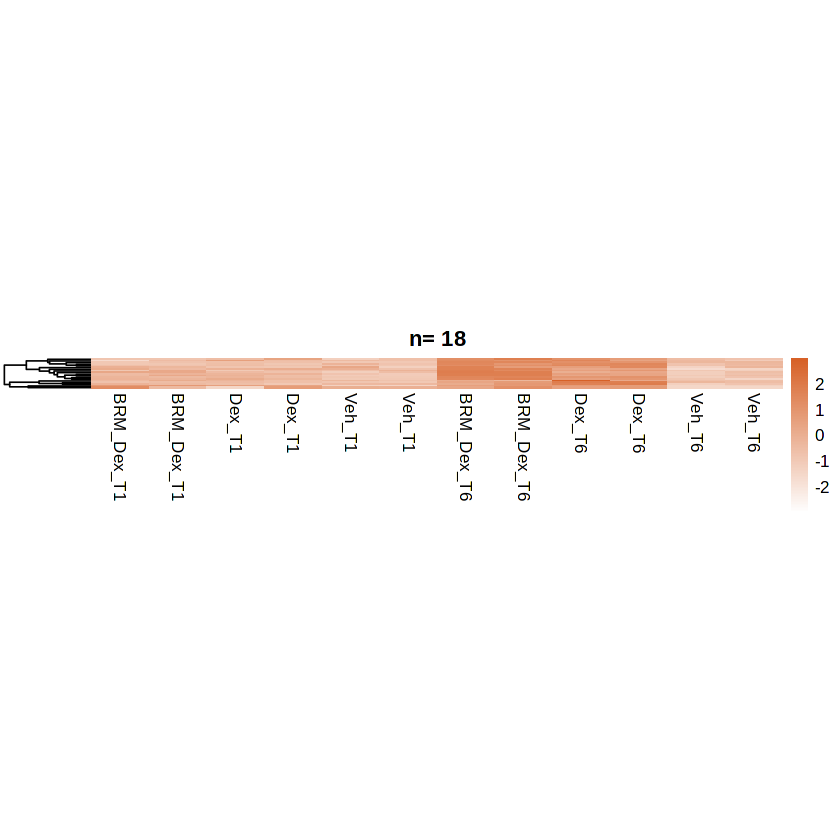

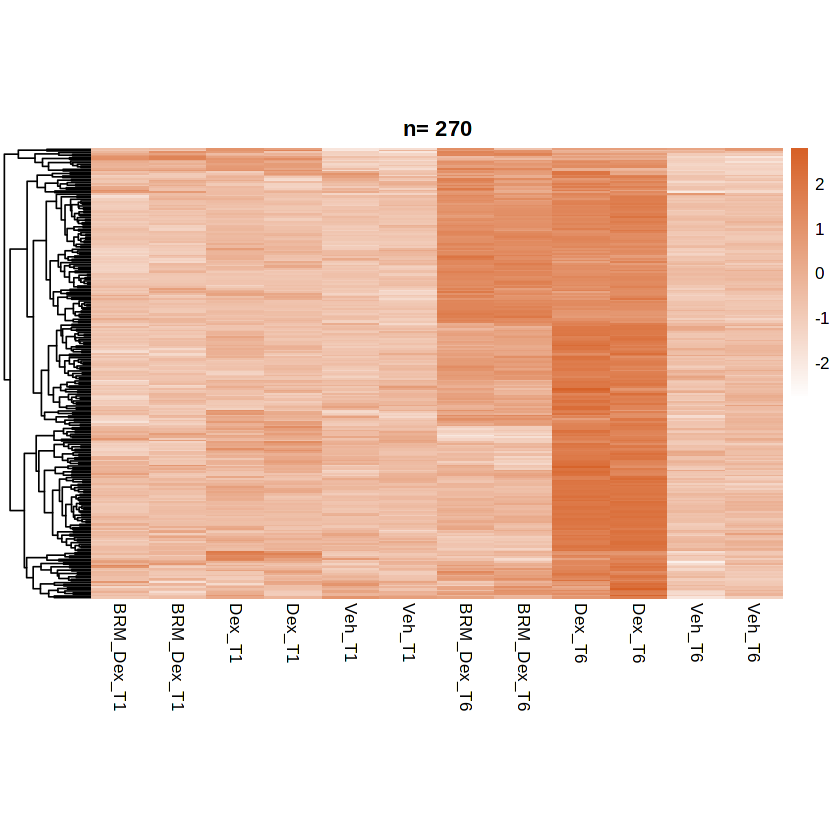

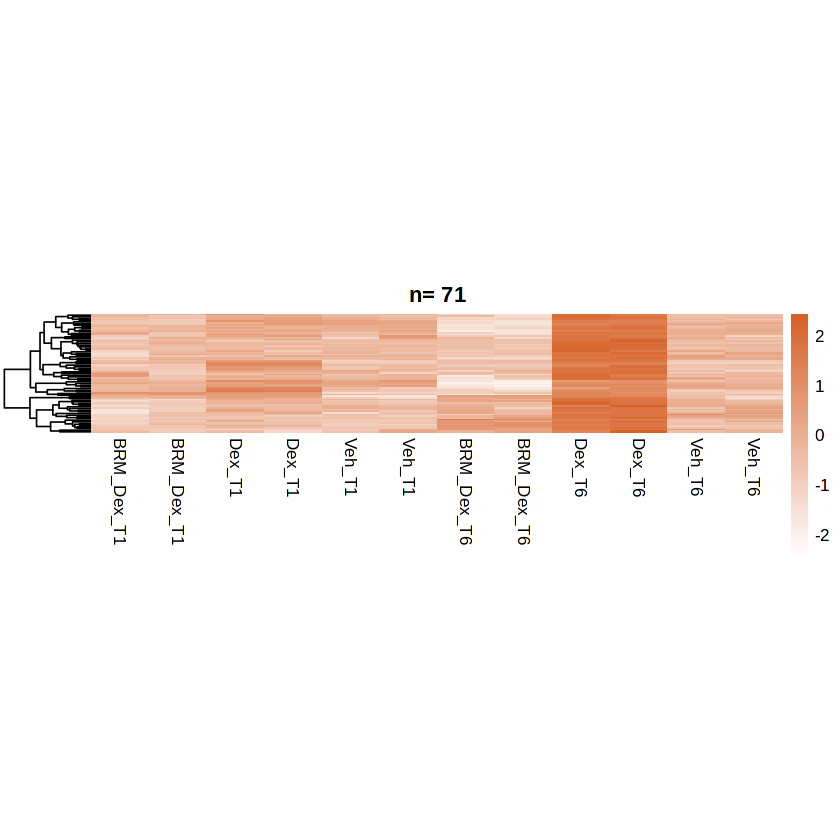

In [43]:
hm_scale(tpm_dex[which(dex_up & brm_6h$change=="up"),], col.data_dex, col.data_dex$group, scale="row", colors=c("white", "#d76127"))
hm_scale(tpm_dex[which(dex_up & brm_6h$change=="ns"),], col.data_dex, col.data_dex$group, scale="row", colors=c("white", "#d76127"))
hm_scale(tpm_dex[which(dex_up & brm_6h$change=="down"),], col.data_dex, col.data_dex$group, scale="row", colors=c("white", "#d76127"))

 int [1:189] 76 114 159 176 179 229 253 325 533 604 ...


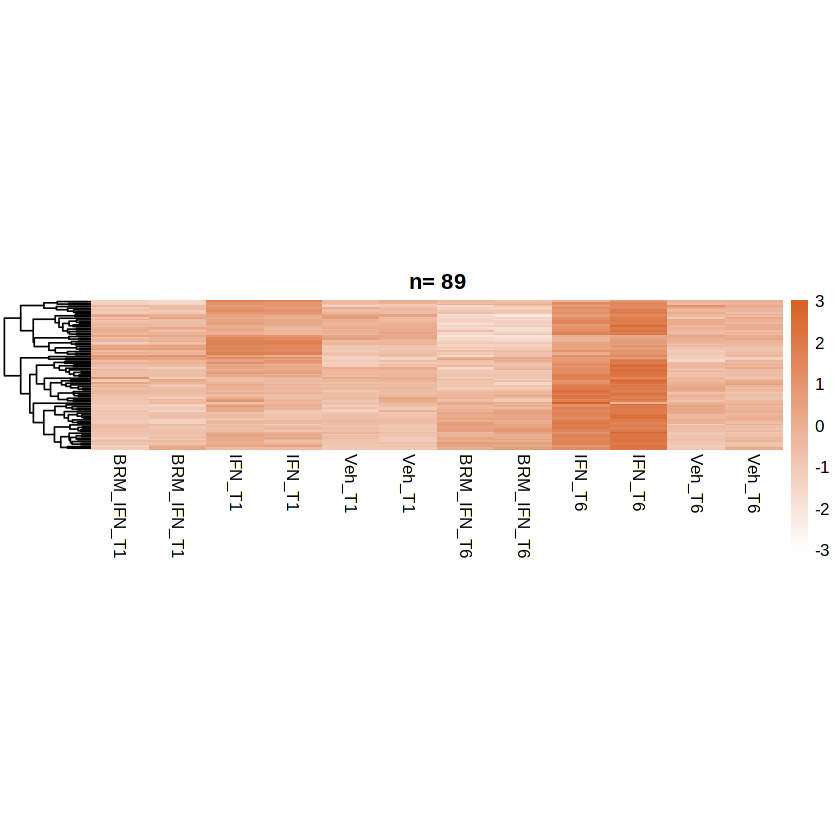

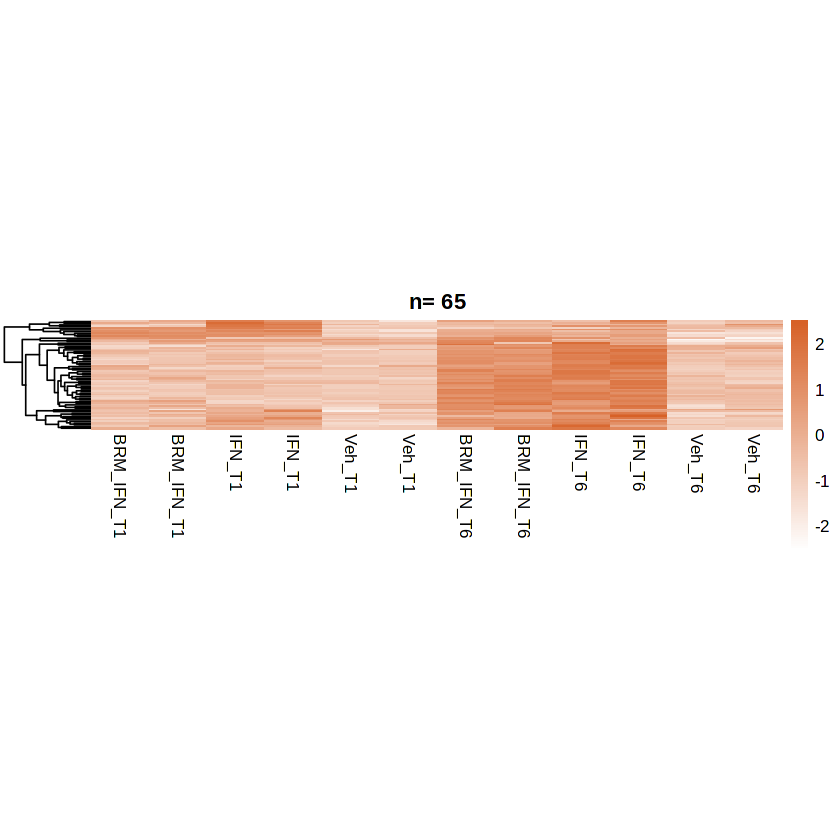

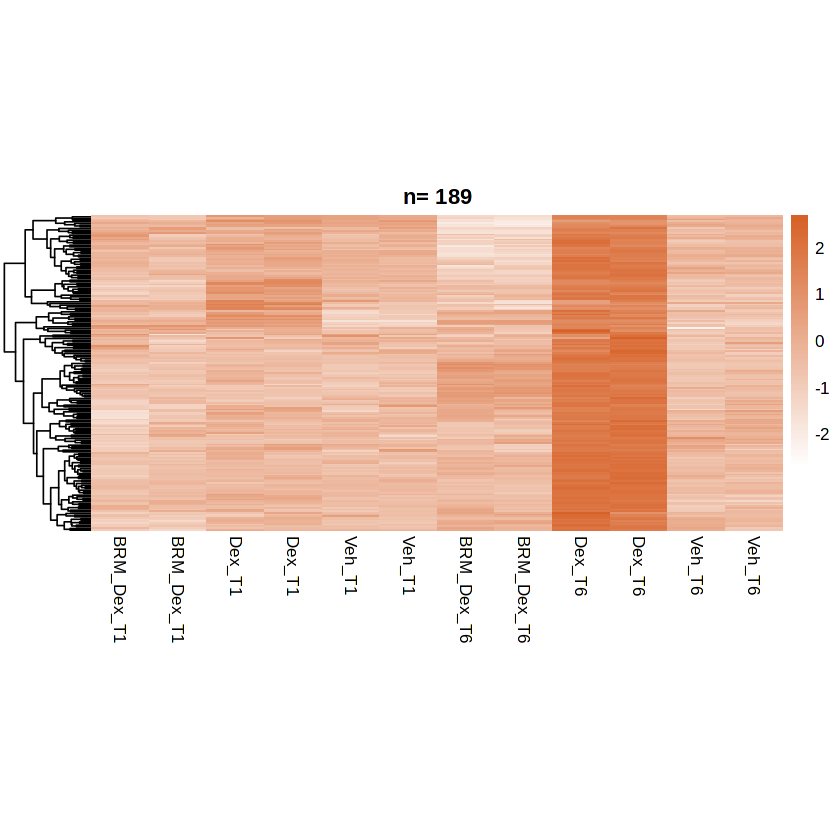

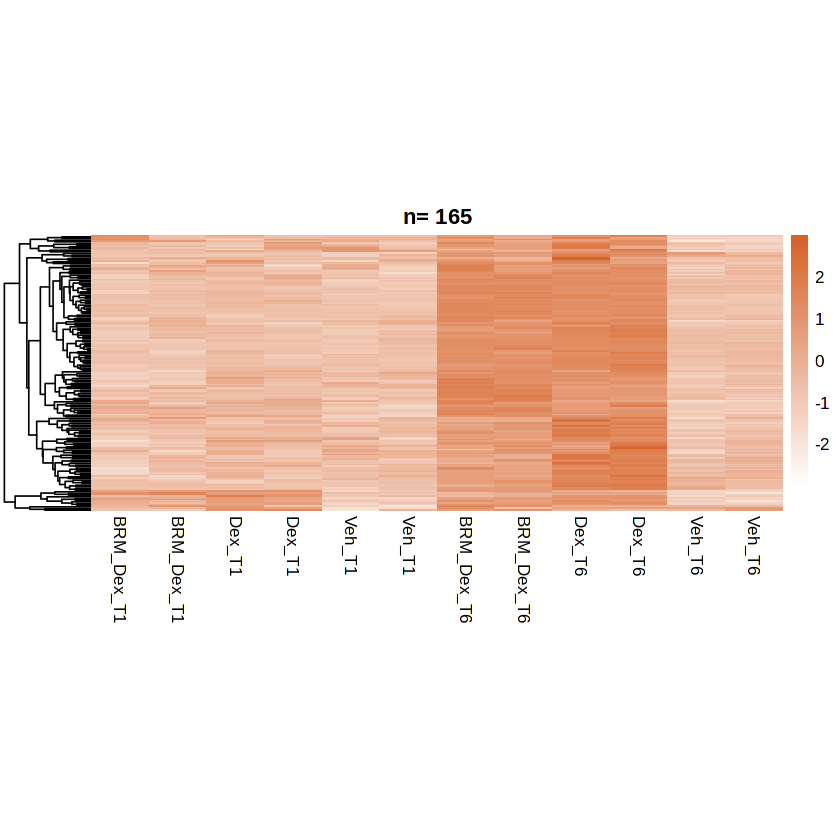

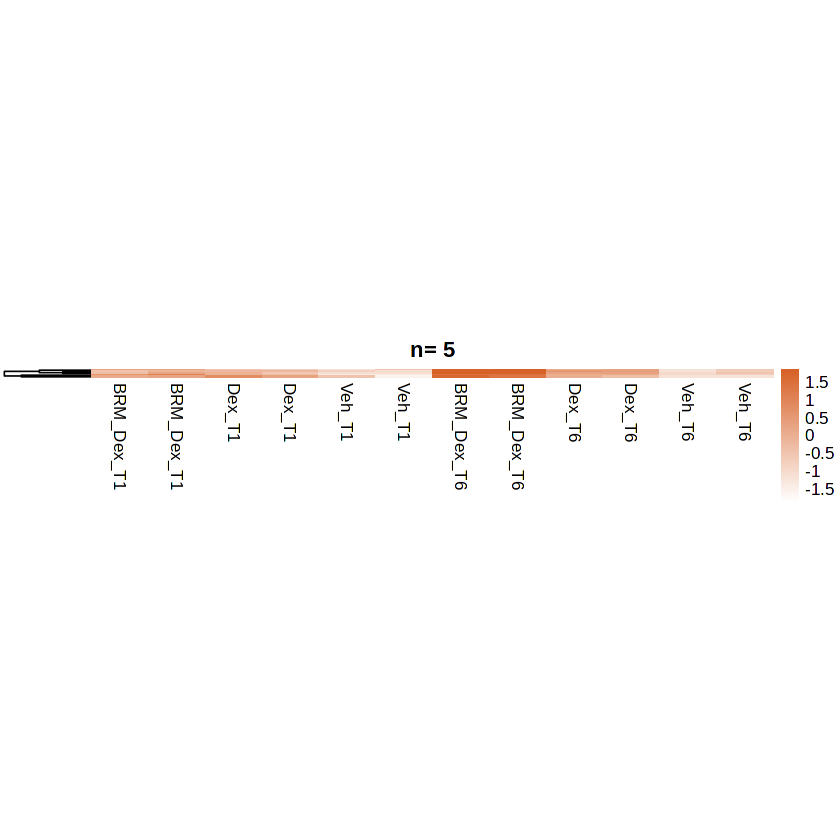

In [89]:
hm_scale(tpm_ifn[which(ifn_up & brm_ifn_6h$change == "down") ,], col.data_ifn, col.data_ifn$group, scale="row", colors=c("white", "#d76127"))
hm_scale(tpm_ifn[which(ifn_up & brm_ifn_6h$change == "ns") ,], col.data_ifn, col.data_ifn$group, scale="row", colors=c("white", "#d76127"))
#hm_scale(tpm_ifn[which(ifn_up & brm_ifn_6h$change == "up") ,], col.data_ifn, col.data_ifn$group, scale="row", colors=c("white", "#d76127"))

hm_scale(tpm_dex[which(dex_up & brm_dex_6h$change == "down") ,], col.data_dex, col.data_dex$group, scale="row", colors=c("white", "#d76127"))
hm_scale(tpm_dex[which(dex_up & brm_dex_6h$change == "ns") ,], col.data_dex, col.data_dex$group, scale="row", colors=c("white", "#d76127"))
hm_scale(tpm_dex[which(dex_up & brm_dex_6h$change == "up") ,], col.data_dex, col.data_dex$group, scale="row", colors=c("white", "#d76127"))


In [90]:
row.data[which(dex_up & brm_dex_6h$change == "ns"),]

,source,type,gene_type,gene_name,level,tag,hgnc_id,havana_gene,artif_dupl,gene_id_base,chr,start,end
,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<lgl>,<chr>,<chr>,<int>,<int>
175,HAVANA,gene,protein_coding,FUCA1,2,NA,HGNC:4006,OTTHUMG00000002965.2,NA,ENSG00000179163,chr1,23845077,23868291
208,HAVANA,gene,protein_coding,PIGV,2,NA,HGNC:26031,OTTHUMG00000004005.9,NA,ENSG00000060642,chr1,26787054,26800660
317,HAVANA,gene,protein_coding,MANEAL,2,NA,HGNC:26452,OTTHUMG00000004317.3,NA,ENSG00000185090,chr1,37793847,37801138
341,HAVANA,gene,protein_coding,SMAP2,2,overlapping_locus,HGNC:25082,OTTHUMG00000007301.7,NA,ENSG00000084070,chr1,40344850,40423327
411,HAVANA,gene,protein_coding,LRRC41,2,NA,HGNC:16917,OTTHUMG00000007810.7,NA,ENSG00000132128,chr1,46261196,46303617
661,HAVANA,gene,protein_coding,ATP1A1,2,NA,HGNC:799,OTTHUMG00000012109.10,NA,ENSG00000163399,chr1,116372668,116410262
675,HAVANA,gene,protein_coding,NOTCH2,2,NA,HGNC:7882,OTTHUMG00000012177.8,NA,ENSG00000134250,chr1,119911553,120100780
715,HAVANA,gene,protein_coding,H4C15,2,NA,HGNC:29607,OTTHUMG00000188201.2,NA,ENSG00000270276,chr1,149854045,149861160
809,HAVANA,gene,protein_coding,EFNA3,2,overlapping_locus,HGNC:3223,OTTHUMG00000035313.2,NA,ENSG00000143590,chr1,155078837,155087539
